<a href="https://colab.research.google.com/github/sofiacicutti/data_science/blob/main/Projeto_Framework_CRISP_DM_Amazon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Por que clientes de assinatura dão nota baixa?

**Como usar:** clique em **Ambiente de execução > Executar tudo**. Não precisa mexer em nada. Cada bloco tem uma explicação antes e o resultado logo depois.

**Dados reais:** avaliações de caixas de assinatura da Amazon (base pública Amazon Reviews 2023, McAuley Lab/UCSD). São clientes dos EUA.

**Pergunta de marketing:** o que leva o cliente a dar nota 1 ou 2, e onde a marca deve agir?

**Pergunta da avaliação final (impacto social):** que mudança a estratégia pode gerar para as pessoas afetadas e quais evidências permitem avaliar essa mudança?

**Mapa do notebook:** Passos 1 a 6 = análise de negócio (CRISP-DM). Passos 7 a 12 = dimensão social: públicos, linha de base, tamanho do teste, quadro das seis etapas, quadro de indicadores e regra de decisão. Passo 13 = gera os slides do pitch em PowerPoint.

## Passo 1. Baixar os dados
Este bloco baixa as avaliações da internet (cerca de 10 MB). Leva alguns segundos.

In [ ]:
import urllib.request, os
base = "https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw/review_categories/Subscription_Boxes.jsonl"
if not os.path.exists("avaliacoes.jsonl"):
    urllib.request.urlretrieve(base, "avaliacoes.jsonl")
print("Dados baixados.")

Dados baixados.


## Passo 2. Abrir a tabela e limpar
Cada linha é uma avaliação. Juntamos título e texto, tiramos avaliações repetidas ou sem texto e criamos a coluna **nota_baixa** (1 = nota 1 ou 2; 0 = nota 3, 4 ou 5).

In [ ]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (8, 4)

df = pd.read_json("avaliacoes.jsonl", lines=True)
df = df.drop_duplicates(["user_id", "parent_asin", "timestamp"])          # tira repetidas
df["texto"] = (df["title"].fillna("") + ". " + df["text"].fillna("")).str.lower()
df = df[df["text"].fillna("").str.strip() != ""]                           # tira sem texto
df["nota_baixa"] = (df["rating"] <= 2).astype(int)

print("Avaliações analisadas:", len(df))
print(f"Parte com nota 1 ou 2: {df.nota_baixa.mean():.1%}")

Avaliações analisadas: 16005
Parte com nota 1 ou 2: 25.1%


## Passo 3. Como estão as notas?
O gráfico mostra quantas avaliações têm cada nota. Repare que as notas extremas (1 e 5) dominam.

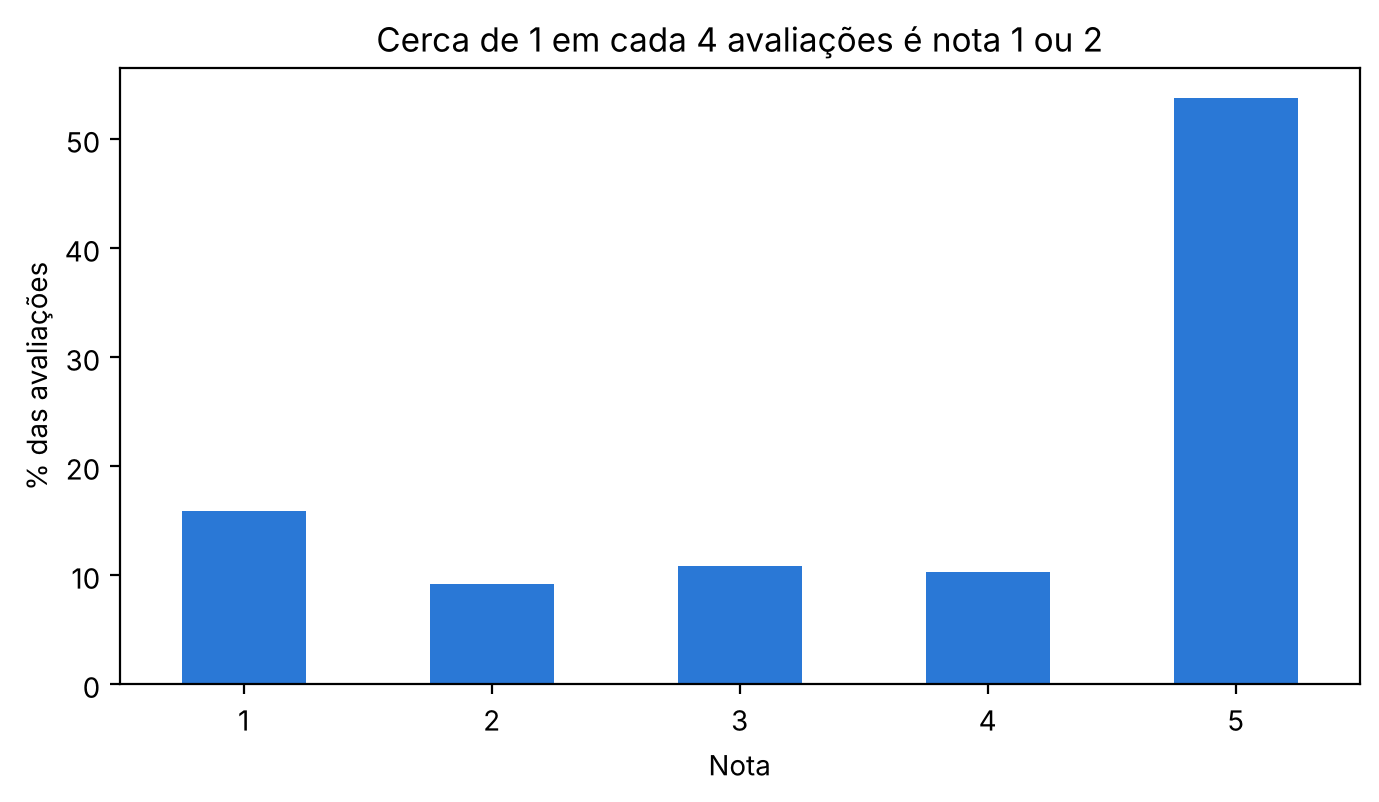

In [ ]:
(df["rating"].value_counts(normalize=True).sort_index() * 100).plot(kind="bar", color="#2a78d6")
plt.title("Cerca de 1 em cada 4 avaliações é nota 1 ou 2")
plt.xlabel("Nota"); plt.ylabel("% das avaliações"); plt.xticks(rotation=0)
plt.show()

## Passo 4. Sobre o que o cliente reclama?
Procuramos palavras-chave nos textos (em inglês) para marcar sete assuntos. Depois comparamos: entre quem **cita** o assunto, quantos deram nota baixa? E entre quem **não cita**?

In [ ]:
temas = {
 "Cobrança e cancelamento": r"\b(charg\w*|bill\w*|cancel\w*|refund\w*|auto[- ]?renew\w*|unsubscrib\w*)\b",
 "Expectativa e decepção":  r"\b(disappoint\w*|expect\w*|misleading|not as (described|advertised)|smaller|tiny|boring)\b",
 "Atendimento":             r"\b(customer (service|support)|support|contact\w*|respon\w*|rude)\b",
 "Preço e valor":           r"\b(price\w*|expensive|overpriced|cost\w*|not worth|worth|value|rip[- ]?off)\b",
 "Qualidade e defeito":     r"\b(quality|poor|flimsy|junk|broke\w*|defective|cheaply made|garbage|trash)\b",
 "Entrega e embalagem":     r"\b(ship\w*|deliver\w*|arriv\w*|late|delay\w*|damag\w*|packag\w*|missing)\b",
 "Presente":                r"\b(gift\w*|birthday|christmas|present)\b",
}
linhas = []
for nome, padrao in temas.items():
    cita = df["texto"].str.contains(padrao, regex=True)
    linhas.append({"Assunto": nome,
                   "Quantas citam": int(cita.sum()),
                   "% nota baixa (quem cita)": round(df.loc[cita, "nota_baixa"].mean() * 100, 1),
                   "% nota baixa (quem não cita)": round(df.loc[~cita, "nota_baixa"].mean() * 100, 1)})
tabela = pd.DataFrame(linhas).sort_values("% nota baixa (quem cita)", ascending=False)
tabela

,Assunto,Quantas citam,% nota baixa (quem cita),% nota baixa (quem não cita)
0,Cobrança e cancelamento,1829,59.9,20.6
1,Expectativa e decepção,2321,53.3,20.3
2,Atendimento,540,44.8,24.4
4,Qualidade e defeito,2396,35.2,23.3
3,Preço e valor,4629,35.1,21.0
5,Entrega e embalagem,2770,28.0,24.5
6,Presente,1759,14.8,26.4


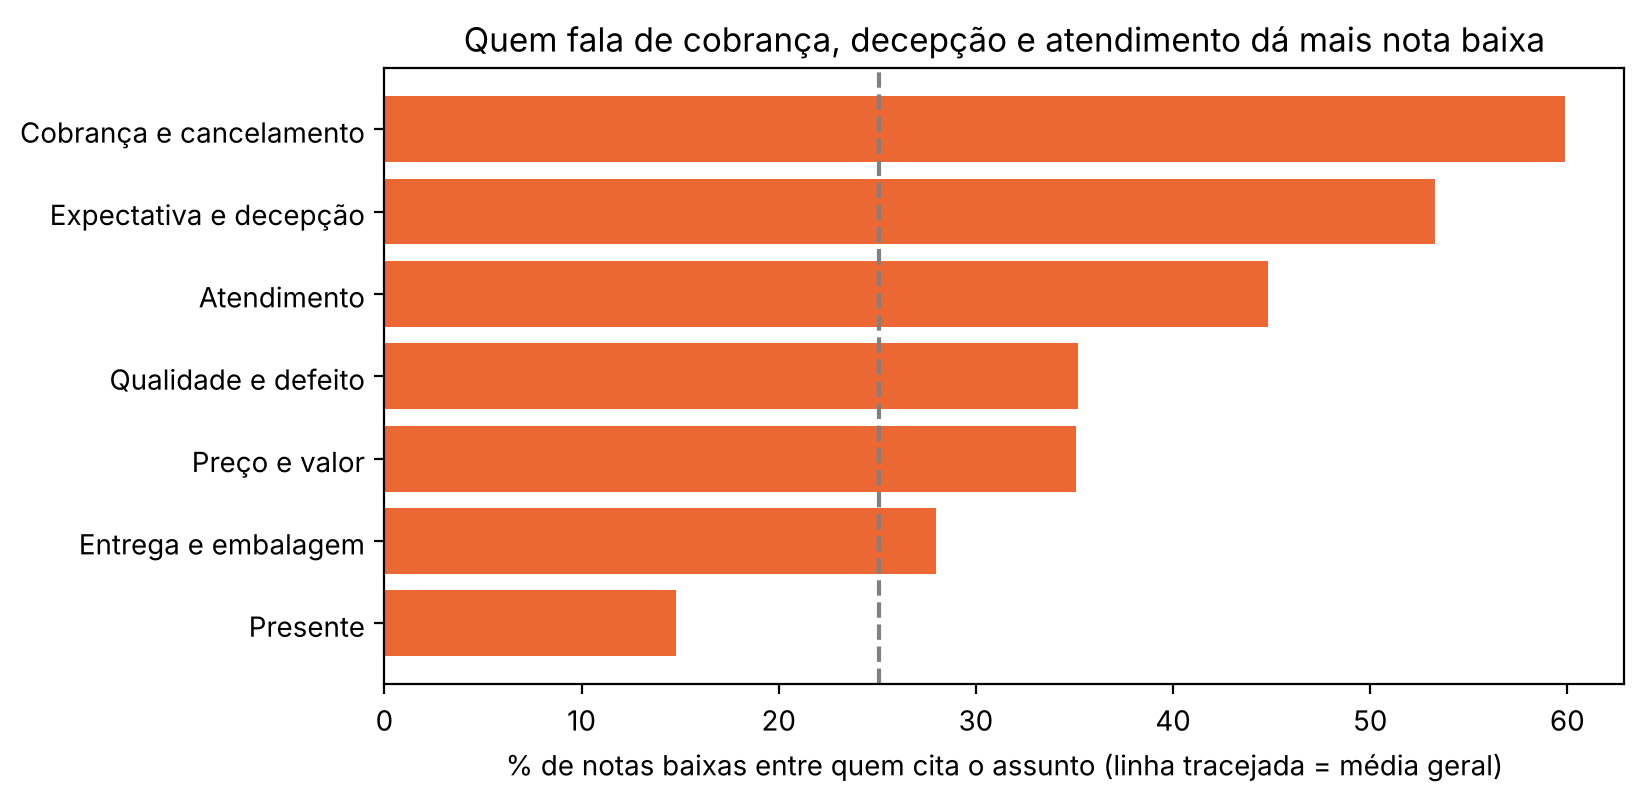

In [ ]:
t = tabela.sort_values("% nota baixa (quem cita)")
plt.barh(t["Assunto"], t["% nota baixa (quem cita)"], color="#eb6834")
plt.axvline(df.nota_baixa.mean() * 100, color="gray", linestyle="--")
plt.title("Quem fala de cobrança, decepção e atendimento dá mais nota baixa")
plt.xlabel("% de notas baixas entre quem cita o assunto (linha tracejada = média geral)")
plt.show()

## Passo 5. Um modelo que lê o texto e aponta quem está insatisfeito
Um modelo de classificação aprende, com 70% das avaliações, quais palavras aparecem junto com nota baixa. Depois testamos nos 30% restantes, que ele nunca viu.

A nota **AUC** mede se o modelo separa bem insatisfeitos de satisfeitos: 0,5 é chute e 1,0 é perfeito.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

treino, teste = train_test_split(df, test_size=0.30, random_state=42, stratify=df["nota_baixa"])
vetor = TfidfVectorizer(ngram_range=(1, 2), min_df=5, stop_words="english", sublinear_tf=True)
X_treino = vetor.fit_transform(treino["texto"])
X_teste = vetor.transform(teste["texto"])

modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_treino, treino["nota_baixa"])
prob = modelo.predict_proba(X_teste)[:, 1]          # chance de ser nota baixa

print(f"AUC no teste: {roc_auc_score(teste['nota_baixa'], prob):.2f}")

AUC no teste: 0.94


In [ ]:
palavras = pd.Series(modelo.coef_[0], index=vetor.get_feature_names_out()).sort_values()
print("Palavras que mais indicam NOTA BAIXA:", ", ".join(palavras.tail(8).index[::-1]))
print("Palavras que mais indicam NOTA ALTA: ", ", ".join(palavras.head(8).index))

Palavras que mais indicam NOTA BAIXA: disappointed, cancelled, cheap, disappointing, waste, terrible, poor, rip
Palavras que mais indicam NOTA ALTA:  love, great, loved, fun, loves, awesome, nice, perfect


## Passo 6. Vale a pena agir? A conta do negócio
A base não tem preço nem cancelamento, então usamos **premissas** (valores em dólar, que você pode mudar). Troque os números abaixo e rode o bloco de novo.

A ideia: entrar em contato (sem desconto) só com quem o modelo aponta como insatisfeito, e ver quanto isso rende a cada 1.000 avaliações.

In [ ]:
# ====== PREMISSAS (pode mudar) ======
ticket_mensal   = 35     # quanto o assinante paga por mês (US$)
margem          = 0.30   # parte do ticket que vira margem
meses_retidos   = 6      # quantos meses a mais fica quem é retido
chance_cancelar = 0.50   # chance de cancelar entre os insatisfeitos
custo_contato   = 2      # custo de cada contato (US$)
recall_meta     = 0.80   # queremos achar pelo menos 80% dos insatisfeitos
# =====================================

valor_retido = ticket_mensal * margem * meses_retidos

# acha o corte mais alto que ainda captura 80% dos insatisfeitos
y = teste["nota_baixa"].to_numpy()
for corte in [i / 100 for i in range(60, 0, -1)]:
    if ((prob >= corte) & (y == 1)).sum() / y.sum() >= recall_meta:
        break
abordados = (prob >= corte).mean() * 1000
acerto = y[prob >= corte].mean()      # entre os abordados, quantos são realmente insatisfeitos
print(f"Corte do modelo: {corte:.2f}  |  Insatisfeitos encontrados: {recall_meta:.0%}  |  Abordados a cada 1.000 avaliações: {abordados:.0f}")
print(f"Entre os abordados, {acerto:.0%} são realmente insatisfeitos (os outros são contatos 'desperdiçados').")

linhas = []
for r in [0.05, 0.10, 0.20]:       # r = parte dos insatisfeitos que o contato consegue reter
    ganho = abordados * acerto * chance_cancelar * r * valor_retido   # só quem é realmente insatisfeito gera ganho
    gasto = abordados * custo_contato
    linhas.append({"Retenção conseguida (r)": f"{r:.0%}", "Gasto (US$)": round(gasto),
                   "Ganho de margem (US$)": round(ganho), "Resultado (US$)": round(ganho - gasto),
                   "Retorno (x)": round(ganho / gasto, 2)})
pd.DataFrame(linhas)

Corte do modelo: 0.35  |  Insatisfeitos encontrados: 80%  |  Abordados a cada 1.000 avaliações: 278
Entre os abordados, 72% são realmente insatisfeitos (os outros são contatos 'desperdiçados').


,Retenção conseguida (r),Gasto (US$),Ganho de margem (US$),Resultado (US$),Retorno (x)
0,5%,556,317,-238,0.57
1,10%,556,634,79,1.14
2,20%,556,1269,713,2.28


## Passo 7. Impacto social: quem é afetado e quem pode ficar de fora?
Até aqui olhamos o **negócio**. Agora olhamos as **pessoas**. O problema social é este: quem assina caixas de assinatura precisa entender **quanto, quando e como cancelar**. Quando a cobrança é confusa ou o cancelamento é difícil, o cliente perde dinheiro, tempo e autonomia.

**Públicos afetados:** (1) assinantes insatisfeitos; (2) consumidores que ficam de fora, porque não escrevem avaliação (idosos, pessoas com deficiência, pouca familiaridade digital); (3) quem compra presente; (4) quem ainda vai comprar e lê as avaliações; (5) equipes de atendimento e produto.

A base **não traz** idade, renda, deficiência nem quem cancelou. Então só conseguimos comparar grupos simples: compra verificada ou não, e avaliação com foto ou sem foto.

In [ ]:
# Compara públicos que a base permite enxergar
df["compra"] = df["verified_purchase"].map({True: "Compra verificada", False: "Compra não verificada"})
df["foto"] = df["images"].apply(lambda x: "Com foto" if len(x) > 0 else "Sem foto")

for coluna in ["compra", "foto"]:
    t = df.groupby(coluna)["nota_baixa"].agg(["count", "mean"])
    t.columns = ["Avaliações", "% nota baixa"]
    t["% nota baixa"] = (t["% nota baixa"] * 100).round(1)
    display(t)

# Gráfico simples
g = df.groupby("compra")["nota_baixa"].mean() * 100
g.plot(kind="bar", color=["#2a78d6", "#eb6834"])
plt.title("Compras não verificadas têm mais nota baixa")
plt.ylabel("% de notas baixas"); plt.xlabel(""); plt.xticks(rotation=0)
plt.show()

### Passo 7 (continuação). Os impactos sociais ligados ao nosso problema
Os impactos sociais precisam estar ligados ao **tema** (avaliações de caixas de assinatura), à **empresa** (Amazon) e ao **problema** (nota baixa). Por isso cada impacto abaixo tem uma evidência calculada nos dados.

Os **impactos 1 e 2 são os principais**; o 3 complementa.

In [ ]:
# Evidências calculadas agora, nos dados
def nota_baixa_se_cita(tema):
    c = df["texto"].str.contains(temas[tema], regex=True)
    return df.loc[c, "nota_baixa"].mean() * 100, df.loc[~c, "nota_baixa"].mean() * 100

cob_cita, cob_nao = nota_baixa_se_cita("Cobrança e cancelamento")
exp_cita, exp_nao = nota_baixa_se_cita("Expectativa e decepção")
v = df.groupby("compra")["nota_baixa"].mean() * 100
dif = v["Compra não verificada"] - v["Compra verificada"]

impactos = pd.DataFrame([
 ["Impacto 1. Transparência e autonomia do consumidor",
  f"Cobrança e cancelamento: {cob_cita:.1f}% de nota baixa contra {cob_nao:.1f}% de quem não cita. Na Amazon, a avaliação pública é a vitrine, então a insatisfação fica visível.",
  "Assinantes insatisfeitos", "I3, I4 e I5"],
 ["Impacto 2. Inclusão e acessibilidade",
  f"O modelo só enxerga quem escreve avaliação. Compras não verificadas têm {v['Compra não verificada']:.1f}% de nota baixa contra {v['Compra verificada']:.1f}% ({dif:.1f} pontos de diferença). A solução precisa funcionar para quem não reclama por escrito.",
  "Quem fica de fora (idosos, pessoas com deficiência, baixa familiaridade digital) e quem recebe presente", "I2, I1 e I7"],
 ["Impacto 3. Informação fiel antes da compra",
  f"Expectativa e decepção: {exp_cita:.1f}% de nota baixa contra {exp_nao:.1f}%. Página fiel ao que será entregue reduz a decepção.",
  "Compradores novos", "I6 e I2"],
], columns=["Impacto social", "Ligação com o tema, a empresa e o problema (evidência nos dados)", "Quem é beneficiado", "Indicadores"])

pd.set_option("display.max_colwidth", None)
impactos.style.set_properties(**{"text-align": "left", "white-space": "normal"})

## Passo 8. Linha de base: onde estamos hoje
**Linha de base** é a situação atual, antes da ação. Sem ela não dá para dizer se a ação mudou alguma coisa. Este bloco separa o que é **observado** (medido nos dados) do que é **esperado** (premissa ou meta, que só o teste confirma).

In [ ]:
# ====== OBSERVADO (calculado agora, com os dados) ======
cita = df["texto"].str.contains(temas["Cobrança e cancelamento"], regex=True)
mencoes_cobranca = cita.mean() * 100                          # % das avaliações que citam cobrança/cancelamento
nota_baixa_entre_quem_cita = df.loc[cita, "nota_baixa"].mean() * 100
por_compra = df.groupby("compra")["nota_baixa"].mean() * 100
diferenca_verificada = por_compra["Compra não verificada"] - por_compra["Compra verificada"]

observado = pd.DataFrame({
    "O que foi medido": [
        "Avaliações que citam cobrança ou cancelamento",
        "Nota baixa entre quem cita cobrança ou cancelamento",
        "Nota baixa geral",
        "Diferença de nota baixa: não verificada menos verificada (pontos percentuais)"],
    "Valor": [f"{mencoes_cobranca:.1f}%", f"{nota_baixa_entre_quem_cita:.1f}%",
              f"{df.nota_baixa.mean() * 100:.1f}%", f"{diferenca_verificada:.1f}"]})

# ====== ESPERADO (premissas e metas: ainda NÃO observado) ======
esperado = pd.DataFrame({
    "O que se espera": [
        "Cancelamento entre insatisfeitos sem ação (premissa)",
        "Queda relativa do cancelamento com a ação (meta)",
        "Clientes que entendem a cobrança e resolvem o problema (meta)"],
    "Valor": ["50%", "15% (de 50% para 42,5%)", "70% ou mais"]})

print("OBSERVADO (medido nos dados):"); display(observado)
print("ESPERADO (só o teste confirma):"); display(esperado)

## Passo 9. Tamanho do teste de 90 dias (teste A/B)
Para saber se a ação **realmente** reduz o cancelamento, a empresa testa com dois grupos de clientes insatisfeitos: um recebe o contato (**ação**) e o outro recebe o atendimento padrão (**controle**). A tabela mostra quantos clientes cada grupo precisa ter. Quanto menor o efeito que queremos detectar, maior o grupo.

(Usamos 5% de significância e 80% de poder, que são os valores padrão. O relatório usa outro método de cálculo e chega a 693 por grupo; aqui sai 690. Em ambos, o resultado é "cerca de 700".)

In [ ]:
from scipy.stats import norm

cancelamento_sem_acao = 0.50                       # premissa do projeto
z = norm.ppf(0.975) + norm.ppf(0.80)               # 5% de significância e 80% de poder

linhas = []
for queda in [0.05, 0.10, 0.15, 0.20]:
    p1 = cancelamento_sem_acao
    p2 = p1 * (1 - queda)                          # cancelamento com a ação
    n = z**2 * (p1 * (1 - p1) + p2 * (1 - p2)) / (p1 - p2)**2
    linhas.append({"Queda relativa do cancelamento": f"{queda:.0%}",
                   "Cancelamento com ação": f"{p2:.1%}",
                   "Insatisfeitos por grupo": round(n)})
tabela_ab = pd.DataFrame(linhas)
display(tabela_ab)

n_meta = int(tabela_ab.loc[2, "Insatisfeitos por grupo"])          # linha da meta de 15%
avaliacoes_necessarias = 2 * n_meta / (abordados / 1000)           # 'abordados' vem do Passo 6
print(f"Para detectar a meta de 15%: cerca de {n_meta} insatisfeitos em cada grupo ({2 * n_meta} no total).")
milhar = lambda v: f"{v:,.0f}".replace(",", ".")      # 1234 vira 1.234
print(f"Como o modelo marca {abordados:.0f} em cada 1.000 avaliações, isso pede cerca de {milhar(avaliacoes_necessarias)} avaliações no período.")
print(f"Custo do contato só no grupo da ação: cerca de US$ {milhar(n_meta * custo_contato)} (premissa de US$ {custo_contato} por contato).")

## Passo 10. Quadro: impacto social nas seis etapas do CRISP-DM
Uma linha para cada etapa, como pede a avaliação. Lembre-se: o impacto social não fica só no final, ele aparece em **todas** as etapas.

In [ ]:
pd.set_option("display.max_colwidth", None)

quadro_crispdm = pd.DataFrame([
 ["Compreensão do negócio", "Qual necessidade e quais públicos?",
  "Objetivo de negócio (queda de 15% no cancelamento) e objetivo social (cliente entende a cobrança e cancela sem barreira). Públicos: assinantes insatisfeitos, quem fica de fora, quem compra presente, compradores novos e equipes.",
  "Quem pode ficar de fora? Quem não escreve avaliação. Quem pode ser prejudicado: quem sofre pressão para não cancelar."],
 ["Compreensão dos dados", "Os dados representam os públicos?",
  "Fonte McAuley Lab, 2017 a agosto de 2023, cerca de 16 mil avaliações de clientes dos EUA, em inglês.",
  "Viés, ausência ou risco à privacidade: só quem avalia aparece; faltam idade, deficiência e cancelamento; o texto livre pode ter dado pessoal."],
 ["Preparação dos dados", "Como proteger e tratar os dados?",
  "Limpeza documentada (repetidas e sem texto), sem nome, e-mail ou endereço, e nenhum grupo pequeno excluído em silêncio.",
  "Perda ou exclusão de registros; palavras-chave erram ironia e negação."],
 ["Modelagem e análise", "Como os resultados variam entre públicos?",
  "Comparação entre compra verificada ou não e com foto ou sem foto; nenhuma característica pessoal no modelo; associação, previsão e causa são coisas diferentes.",
  "Discriminação ou conclusão indevida: tratar clientes diferente por compra não verificada, ou achar que a associação prova causa."],
 ["Avaliação", "Há benefício social e resultado de negócio?",
  "Critérios de negócio (acerto do modelo e retorno) somados a critérios sociais (resolução do problema, cancelamento sem barreira, equidade).",
  "Efeitos não previstos: retenção por obstrução, contato indevido, contato indesejado."],
 ["Implantação", "Como acompanhar e corrigir a ação?",
  "Teste A/B de 90 dias, sete indicadores com meta, fonte e responsável, revisão trimestral e canal de escuta.",
  "Falta de monitoramento ou escuta: sem linha de base nem indicador de mudança para o público; o modelo envelhece."],
], columns=["Etapa", "Questão social considerada", "Evidência ou decisão do projeto", "Risco ou limitação"])

quadro_crispdm.style.set_properties(**{"text-align": "left", "white-space": "normal"})

## Passo 11. Quadro de indicadores
São **7 indicadores** (a avaliação pede no mínimo 3). Dois deles (**I2 e I3**) medem **mudança para o público**, e não apenas alcance ou cliques. Visualizações e cliques não provam impacto social.

As linhas de base de I6 e I7 vêm dos dados do Passo 8. As demais metas são **propostas do grupo** e devem ser revistas com os números reais da empresa.

**Atenção:** como este notebook usa uma limpeza e palavras-chave mais simples, as linhas de base saem um pouco diferentes das do relatório (por exemplo, 11,4% de menções a cobrança aqui, contra 10,6% no relatório). Na apresentação, use os números do relatório.

In [ ]:
quadro_indicadores = pd.DataFrame([
 ["I1. Acesso: cobertura do contato ativo",
  "Contatos feitos em até 72 h ÷ avaliações sinalizadas × 100",
  "Base: sem contato ativo hoje (confirmar). Meta: 90% ou mais",
  "CRM e fila de atendimento; semanal", "Atendimento"],
 ["I2. Experiência: clareza e conclusão da tarefa",
  "Participantes que acham a cobrança e concluem o cancelamento em até 3 min ÷ participantes × 100; mais a pergunta 'Ficou claro quanto e quando você será cobrado?'",
  "Base: medir na página atual. Meta: 85% de conclusão e 80% de 'sim'",
  "Teste de usabilidade e pesquisa de 1 pergunta; antes e depois, depois trimestral", "Produto"],
 ["I3. Resultado: resolução confirmada pelo cliente",
  "Contatados com problema resolvido em até 7 dias e confirmado pelo cliente ÷ contatados × 100",
  "Base: não medida. Meta: 70% no primeiro ciclo e 80% depois",
  "Pergunta pós-atendimento; semanal e mensal", "Atendimento"],
 ["I4. Resultado de negócio: cancelamento em 90 dias",
  "Queda relativa = 1 − (cancelamento do grupo com ação ÷ cancelamento do controle)",
  "Base: 50% (premissa). Meta: 42,5% (queda de 15%)",
  "Base de assinaturas; mensal", "CRM e Dados"],
 ["I5. Salvaguarda: cancelamento sem barreira",
  "Pedidos de cancelamento concluídos em 1 contato, sem oferta obrigatória ÷ pedidos × 100",
  "Base: medir antes do teste. Meta: 100%",
  "Registros do fluxo de cancelamento e reclamações; mensal", "Produto e Jurídico"],
 ["I6. Evidência pública: menções a cobrança ou cancelamento",
  "Novas avaliações que citam cobrança ou cancelamento ÷ novas avaliações × 100",
  f"Base: {mencoes_cobranca:.1f}% das avaliações ({nota_baixa_entre_quem_cita:.1f}% com nota baixa). Meta: {mencoes_cobranca * 0.8:.1f}% ou menos em 6 meses",
  "Coleta das avaliações; trimestral", "Marketing e Dados"],
 ["I7. Equidade: diferença entre grupos",
  "Diferença em pontos percentuais de I1 e I3 entre grupos (compra verificada ou não, canal, idioma)",
  f"Base: não medida (nota baixa difere {diferenca_verificada:.1f} pontos entre não verificadas e verificadas). Meta: 5 pontos ou menos",
  "CRM e pesquisa pós-atendimento; mensal", "Dados"],
], columns=["Indicador", "Como será calculado", "Linha de base e meta", "Fonte e periodicidade", "Responsável"])

quadro_indicadores.style.set_properties(**{"text-align": "left", "white-space": "normal"})

## Passo 12. Regra de decisão: aprovar, ajustar ou interromper
Depois do teste, a empresa precisa decidir. Esta regra aplica os critérios do relatório. **Troque os números abaixo pelos resultados reais do teste** (os valores atuais são só um **exemplo**) e rode o bloco de novo.

- **Interromper:** se houve barreira ao cancelamento ou incidente de privacidade.
- **Aprovar e ampliar:** se o cancelamento caiu 15% ou mais (com significância), a resolução foi de 70% ou mais e a diferença entre grupos é de 5 pontos ou menos.
- **Ajustar:** nos demais casos.

In [ ]:
# ====== RESULTADOS DO TESTE DE 90 DIAS (EXEMPLO: troque pelos números reais) ======
n_por_grupo               = 700     # insatisfeitos em cada grupo
cancelamento_controle     = 0.50    # % que cancelou no grupo sem ação
cancelamento_acao         = 0.42    # % que cancelou no grupo com ação
resolucao_confirmada      = 0.72    # % dos contatados com problema resolvido (I3)
cancelamento_sem_barreira = 1.00    # % de pedidos de cancelamento concluídos sem barreira (I5)
diferenca_entre_grupos_pp = 4       # diferença em pontos percentuais entre grupos (I7)
incidente_privacidade     = False   # houve vazamento ou uso indevido de dados?
# ====================================================================

queda = 1 - cancelamento_acao / cancelamento_controle

# teste simples: a diferença entre os dois grupos pode ser acaso?
p_junto = (cancelamento_controle + cancelamento_acao) / 2
erro = (p_junto * (1 - p_junto) * 2 / n_por_grupo) ** 0.5
z_teste = (cancelamento_controle - cancelamento_acao) / erro
p_valor = 2 * (1 - norm.cdf(abs(z_teste)))

print(f"Queda relativa do cancelamento: {queda:.1%}  |  p-valor: {p_valor:.4f}  (abaixo de 0,05 = diferença real)")
print(f"Resolução confirmada: {resolucao_confirmada:.0%}  |  Cancelamento sem barreira: {cancelamento_sem_barreira:.0%}  |  Diferença entre grupos: {diferenca_entre_grupos_pp} pontos")

if cancelamento_sem_barreira < 1 or incidente_privacidade:
    decisao = "INTERROMPER: houve barreira ao cancelamento ou incidente de privacidade. Pausar em até 48 h e corrigir."
elif queda >= 0.15 and p_valor < 0.05 and resolucao_confirmada >= 0.70 and diferenca_entre_grupos_pp <= 5:
    decisao = "APROVAR E AMPLIAR: metas de negócio e sociais atingidas."
else:
    decisao = "AJUSTAR: alguma meta não foi atingida. Manter a correção da página e reduzir o contato em massa até corrigir."
print("\nDecisão:", decisao)

## Passo 13. Os slides do pitch

In [ ]:
%pip install -q python-pptx

In [ ]:
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor

AZUL, CLARO, LARANJA = RGBColor(0x14, 0x21, 0x3D), RGBColor(0xF7, 0xF5, 0xF0), RGBColor(0xE8, 0x74, 0x2A)
TEXTO_SUAVE_CLARO, TEXTO_SUAVE_ESCURO = RGBColor(0x4A, 0x55, 0x68), RGBColor(0xC9, 0xD3, 0xE3)

# ====== TEXTO DOS SLIDES (pode editar) ======
# fundo: "claro", "escuro" ou "laranja" | destaque = número grande (pode ficar vazio "")
slides = [
 dict(fundo="escuro", rotulo="AMAZON · CAIXAS DE ASSINATURA",
      titulo="Nota baixa custa caro. E atrás de cada nota há uma pessoa.", destaque="",
      linhas=["Como transformar avaliações ruins em clientes que ficam e em benefício real para quem assina.",
              "Ciência de Dados | Marketing Digital | CEUB · Apresentação de 25/11/2026"]),
 dict(fundo="claro", rotulo="O PROBLEMA", titulo="1 em 4 avaliações tem nota 1 ou 2", destaque="1 em 4",
      linhas=["Nota baixa afasta quem ainda vai comprar e avisa quem vai cancelar.",
              "Base real: 15.997 avaliações limpas, 25,1% com nota baixa (Amazon Reviews 2023, EUA)."]),
 dict(fundo="claro", rotulo="A DESCOBERTA", titulo="O que o cliente escreve explica a nota", destaque="60,0%",
      linhas=["de nota baixa entre quem fala de cobrança ou cancelamento (contra 20,9%). Chance 4,46 vezes maior.",
              "50,4% entre quem fala de expectativa ou decepção (contra 19,6%). Chance 3,76 vezes maior.",
              "Associação, não prova de causa."]),
 dict(fundo="escuro", rotulo="A FERRAMENTA", titulo="O texto avisa quem está insatisfeito", destaque="80,7%",
      linhas=["dos insatisfeitos são captados por um modelo que lê o texto, contatando 29% das avaliações.",
              "AUC 0,93 (0,5 seria chute). Modelo treinado em inglês."]),
 dict(fundo="claro", rotulo="A PROPOSTA", titulo="Cobrança clara e saída simples", destaque="",
      linhas=["AÇÃO A · Contato ativo, sem desconto: resposta em até 72 horas, em linguagem simples.",
              "AÇÃO B · Página fiel ao que chega: preço, recorrência, data da próxima cobrança e o que vem na caixa.",
              "AÇÃO C · Canal de escuta: pergunta curta após o atendimento e revisão mensal dos casos."]),
 dict(fundo="claro", rotulo="A CONTA DO NEGÓCIO", titulo="Sem desconto, a ação se paga", destaque="",
      linhas=["Retenção de 5% dos abordados: −US$ 267 por 1.000 avaliações (retorno 0,54x, prejuízo).",
              "Retenção de 10%: +US$ 52 (retorno 1,09x, paga e sobra).",
              "Retenção de 20%: +US$ 690 (retorno 2,18x, lucro).",
              "Com desconto a conta não fecha em nenhum cenário. Premissas do grupo: ticket US$ 35, margem 30%, contato US$ 2."]),
 dict(fundo="claro", rotulo="IMPACTO SOCIAL", titulo="Quem ganha com isso", destaque="",
      linhas=["IMPACTO 1 · Transparência e autonomia: o assinante entende a cobrança e cancela quando quiser.",
              "IMPACTO 2 · Inclusão e acessibilidade: a solução funciona também para quem não reclama por escrito (idosos, pessoas com deficiência).",
              "IMPACTO 3 · Informação fiel antes da compra: a página mostra o que a pessoa vai receber."]),
 dict(fundo="laranja", rotulo="A REGRA QUE NÃO NEGOCIAMOS", titulo="Cancelar tem que ser tão fácil quanto assinar.", destaque="",
      linhas=["Reter cliente por obstrução ou pressão é prática abusiva. Se acontecer, o projeto falhou, mesmo que o cancelamento caia.",
              "Salvaguardas: sem desconto, revisão humana antes do contato, no máximo um contato e um lembrete."]),
 dict(fundo="claro", rotulo="COMO VAMOS PROVAR", titulo="Teste de 90 dias, com metas para as pessoas", destaque="",
      linhas=["Teste A/B: cerca de 700 insatisfeitos com contato e 700 com atendimento padrão.",
              "Problema resolvido, confirmado pelo cliente: 70% ou mais (mudança para o público).",
              "Clareza da cobrança e do cancelamento: 85% concluem a tarefa (mudança para o público).",
              "Cancelamento em 90 dias: de 50% para 42,5%.  Cancelamento sem barreira: 100%.",
              "Diferença entre grupos: 5 pontos ou menos."]),
 dict(fundo="escuro", rotulo="A DECISÃO", titulo="Ao fim do teste, uma regra clara", destaque="",
      linhas=["APROVAR E AMPLIAR · cancelamento cai 15% ou mais, resolução de 70% ou mais, diferença entre grupos de até 5 pontos.",
              "AJUSTAR · alguma meta não foi atingida: manter a página corrigida e reduzir o contato em massa.",
              "INTERROMPER · barreira ao cancelamento, incidente de privacidade ou dano a público vulnerável (pausa em até 48 horas)."]),
 dict(fundo="claro", rotulo="LIMITES, DITOS COM HONESTIDADE", titulo="O que os dados ainda não provam", destaque="",
      linhas=["Clientes dos EUA, não do Brasil; dados públicos, não da Amazon.",
              "Só quem escreve avaliação aparece; a base não mostra quem cancelou.",
              "O retorno depende das premissas do grupo.",
              "É associação, não causa: só o teste A/B confirma o efeito."]),
 dict(fundo="escuro", rotulo="O PEDIDO", titulo="Aprovar um teste de 90 dias.", destaque="",
      linhas=["Contato ativo sem desconto, página fiel ao que chega e cancelamento sem barreira.",
              "Para o negócio: menos cancelamento.  Para as pessoas: cobrança clara e saída simples."]),
]
# ============================================

def escreve(slide, texto, x, y, larg, alt, tamanho, cor, negrito=False):
    caixa = slide.shapes.add_textbox(Inches(x), Inches(y), Inches(larg), Inches(alt))
    quadro = caixa.text_frame
    quadro.word_wrap = True
    paragrafo = quadro.paragraphs[0]
    run = paragrafo.add_run()
    run.text = texto
    run.font.size, run.font.bold, run.font.color.rgb = Pt(tamanho), negrito, cor
    run.font.name = "Calibri"
    return quadro

apresentacao = Presentation()
apresentacao.slide_width, apresentacao.slide_height = Inches(13.333), Inches(7.5)

for s in slides:
    slide = apresentacao.slides.add_slide(apresentacao.slide_layouts[6])      # slide em branco
    fundo = {"claro": CLARO, "escuro": AZUL, "laranja": LARANJA}[s["fundo"]]
    slide.background.fill.solid(); slide.background.fill.fore_color.rgb = fundo
    cor_texto = CLARO if s["fundo"] == "escuro" else AZUL
    cor_suave = TEXTO_SUAVE_ESCURO if s["fundo"] == "escuro" else (AZUL if s["fundo"] == "laranja" else TEXTO_SUAVE_CLARO)
    cor_destaque = RGBColor(0xF2, 0x8C, 0x38) if s["fundo"] == "escuro" else RGBColor(0xC4, 0x57, 0x1A)

    escreve(slide, s["rotulo"], 0.9, 0.6, 11.5, 0.5, 16, cor_suave, negrito=True)
    escreve(slide, s["titulo"], 0.9, 1.1, 11.5, 1.4, 38, cor_texto, negrito=True)
    y = 2.7
    if s["destaque"]:
        escreve(slide, s["destaque"], 0.9, 2.5, 11.5, 1.6, 80, cor_destaque, negrito=True)
        y = 4.2
    for linha in s["linhas"]:
        quadro = escreve(slide, linha, 0.9, y, 11.5, 0.9, 20, cor_suave)
        y += 0.85

nome_arquivo = "Pitch_Amazon_Impacto_Social.pptx"
apresentacao.save(nome_arquivo)
print(f"Slides criados: {len(slides)}. Arquivo: {nome_arquivo}")

try:
    from google.colab import files          # no Colab, baixa o arquivo direto
    files.download(nome_arquivo)
except ImportError:
    print("Fora do Colab: o arquivo ficou salvo na pasta atual.")

## Conclusão (para a apresentação)
- **Observação 1:** quem fala de **cobrança/cancelamento** dá nota baixa em cerca de 60% dos casos, contra cerca de 21% de quem não fala.
- **Observação 2:** quem fala de **expectativa/decepção** dá nota baixa em cerca de 53%, contra cerca de 20%.
- **Campanha:** contato ativo, **sem desconto**, com quem demonstra esses sinais, mais ajuste da página do produto para a entrega ficar igual ao prometido.
- **Cuidado com os dados:** tratar avaliações como dado pessoal (LGPD) e não cruzar com outras bases para identificar o autor.
- **Limites:** os números deste notebook simples diferem um pouco do projeto completo (limpeza e palavras-chave mais simples); as conclusões são as mesmas.
- **Mais limites:** dados dos EUA; a base não mostra cancelamento; o retorno em dólar depende das premissas; só um teste A/B confirma o efeito.

### Resposta à pergunta orientadora (impacto social)
**Que mudança a estratégia pode gerar para as pessoas afetadas?** O assinante passa a entender a cobrança, ter o problema resolvido em poucos dias ou cancelar sem barreira, e o comprador novo encontra na página o que de fato receberá.

**Quais evidências permitem avaliar essa mudança?** Os dados atuais **mostram o problema** (Passos 4 a 8). A **mudança** só será comprovada no teste, pelos indicadores I2 (clareza), I3 (resolução confirmada), I4 (cancelamento), I5 (cancelamento sem barreira) e I7 (equidade entre grupos).

### Considerações finais
A estratégia proposta contribui para reduzir a dificuldade de entender a cobrança e de cancelar enfrentada por assinantes ao contatar de forma ativa e sem desconto quem demonstra insatisfação, corrigir a página do produto e garantir cancelamento sem barreira. Os dados analisados indicam que quem cita cobrança ou cancelamento dá nota baixa em cerca de 60% das vezes e que o texto da avaliação prevê a nota baixa, mas ainda não permitem confirmar que o contato reduza o cancelamento, que melhore a compreensão e a resolução para o público, nem que o resultado valha para clientes brasileiros. A organização deverá acompanhar os indicadores I1 a I7 e revisar a ação quando a queda do cancelamento ficar abaixo de 15%, quando o cancelamento deixar de ser feito sem barreira ou quando a diferença entre grupos passar de 5 pontos, conciliando o objetivo de negócio com o benefício esperado para os assinantes, inclusive os que não escrevem avaliações.